<a href="https://colab.research.google.com/github/faisu6339-glitch/LLMs/blob/main/LangChain_Memory.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Detailed Guide to LangChain Memory

In conversational applications, a critical component is the ability to refer to information introduced earlier in the conversation. At its simplest, this ability to store and retrieve past interactions is called **Memory**.

LangChain provides a variety of utilities for adding memory to a system. These utilities can be used on their own or integrated seamlessly into chains.

### Core Concepts
A memory system needs to support two basic actions:
1. **Reading**: Reading historical messages to run the current prompt.
2. **Writing**: Writing the current turn's input and output back into the history for future turns.

### Key Memory Types
* **`ConversationBufferMemory`**: The simplest form of memory, which simply keeps a list of the previous chat messages in history and passes them directly into the prompt context.
* **`ConversationBufferWindowMemory`**: Keeps a sliding window of the most recent $K$ interactions. This is useful for keeping the prompt size manageable.
* **`ConversationSummaryMemory`**: Creates a summary of the conversation over time and injects that summary into the prompt, helping compress long-running chats.
* **`ConversationSummaryBufferMemory`**: A hybrid approach that keeps a buffer of recent interactions but compiles older interactions into a summary once they exceed a certain token limit.

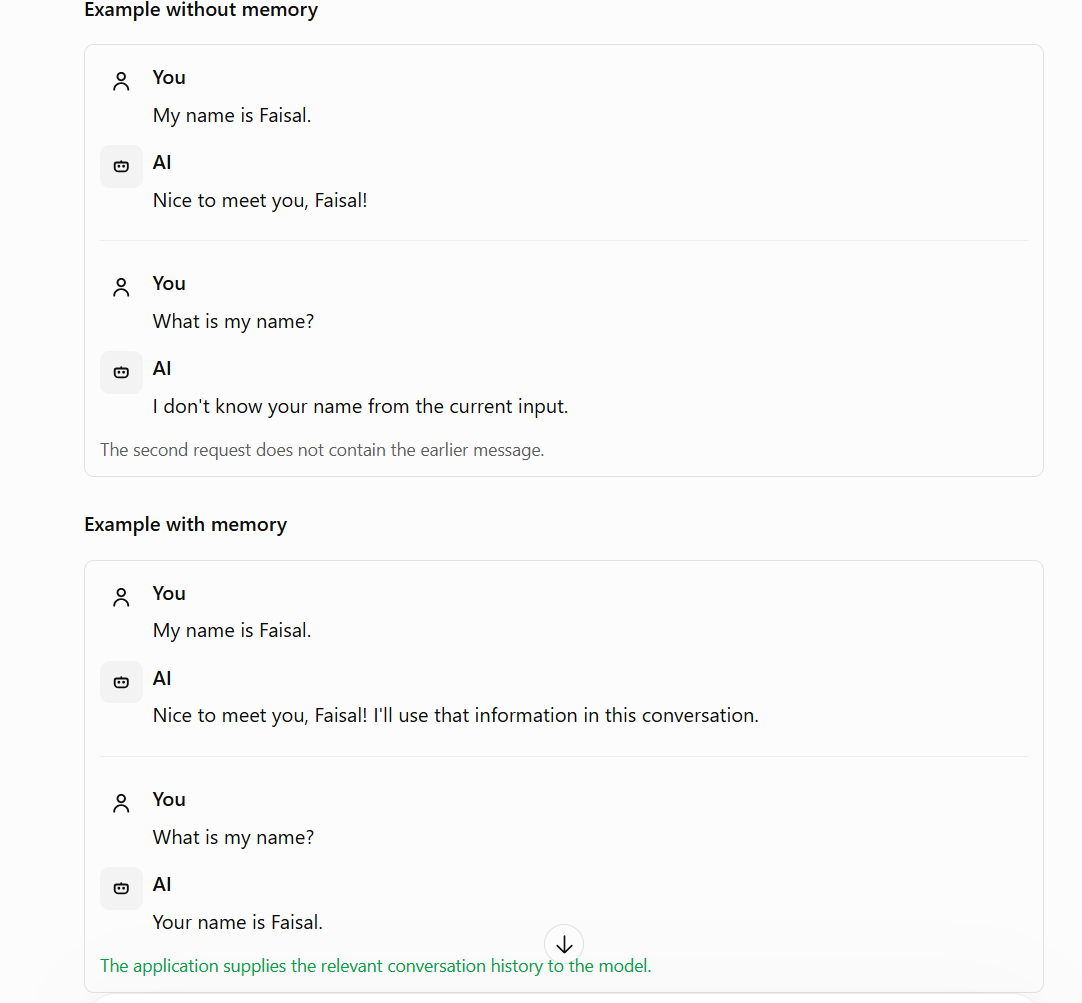

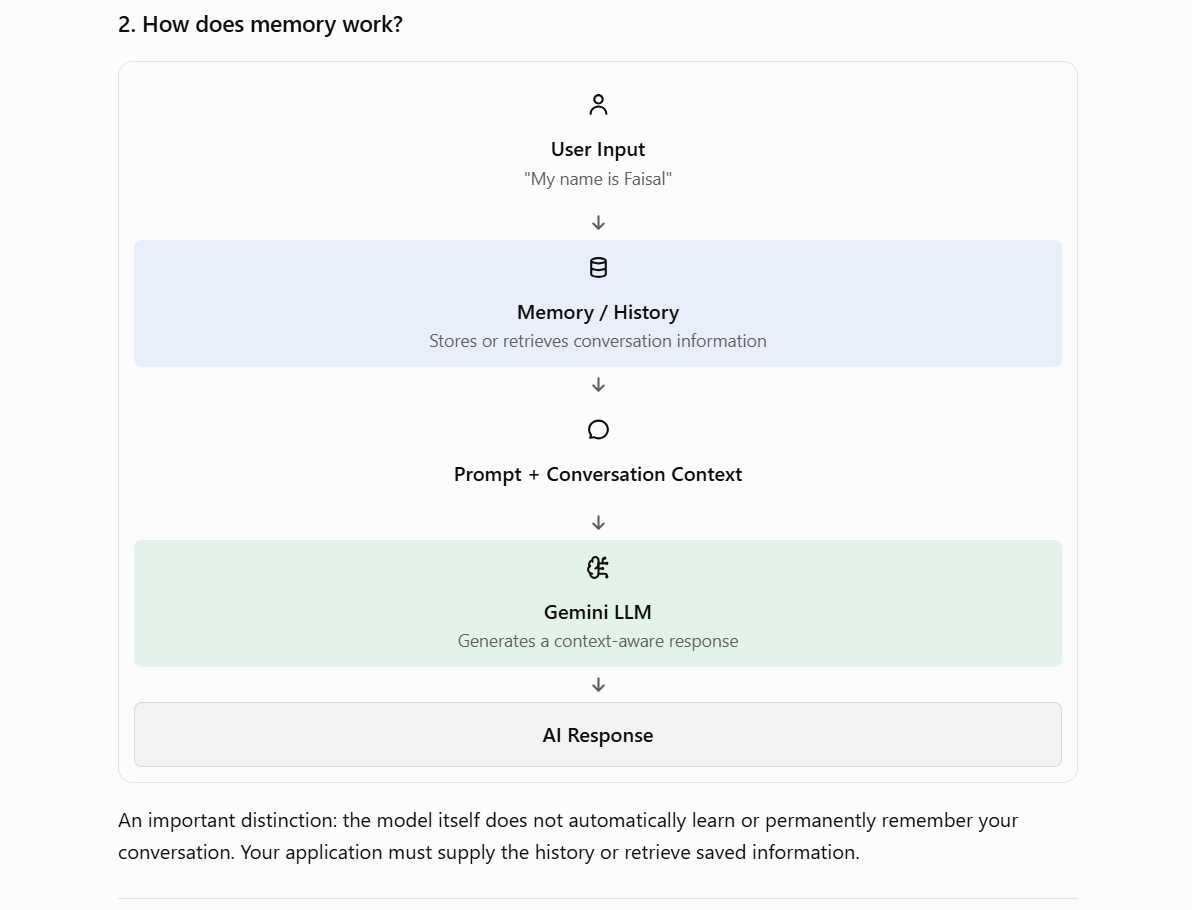

3. Types of memory you should learn
Modern LangChain development distinguishes short-term conversation state from long-term memory. Older tutorials also teach several classic memory classes, many of which are now deprecated.

GitHub
+2



Memory concept	What it does	Example
Chat message history	Stores user and AI messages	Remembers what you asked earlier
Buffer memory	Keeps the entire conversation	Retains all messages in a chat
Window memory	Keeps recent messages only	Remembers the last few turns
Summary memory	Compresses older conversation into a summary	Remembers the main points of a long discussion
Long-term memory	Saves information across conversations	Remembers your preferred programming language
Entity memory	Tracks information about people or things	Stores facts about a project
Persistent memory	Saves state to a database or durable storage	Retrieves history after restarting an app
The classic Buffer, Window, Summary, and Entity classes are useful to understand conceptually, but don't start a new project by relying on their legacy APIs. We'll use modern runnable-based history first, then move to LangGraph persistence and long-term memory.

LangChain Reference
+1

In [1]:
# Install necessary packages
!pip install -q langchain langchain-community

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 18.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 14.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 2.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [4]:
!pip install -q openai

In [5]:
!pip install -q -U langchain langchain-core langchain-openai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.4/166.4 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 573.3/573.3 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.1/146.1 kB 3.8 MB/s eta 0:00:00


In [7]:
from google.colab import userdata
from openai import OpenAI

client = OpenAI(
    base_url="https://integrate.api.nvidia.com/v1",
    api_key=userdata.get("NVIDIA_API_KEY")
)

response = client.chat.completions.create(
    model="nvidia/nemotron-3.5-lightning-30b-a3b",
    messages=[
        {"role": "user", "content": "What is Langhchain memory? Explain briefly."}
    ],
    temperature=1,
    top_p=0.95,
    max_tokens=2048
)

message = response.choices[0].message

print("Answer:", message.content)
print("Reasoning:", getattr(message, "reasoning_content", None))
print("Finish reason:", response.choices[0].finish_reason)

Answer: LangChain memory is a feature that lets large language models retain and reference previous parts of a conversation across multiple interactions. It stores chat history, summarizes it, or buffers tokens so the model doesn't start from scratch each turn, enabling coherent, context-aware multi-turn dialogues.
Reasoning: Here's a thinking process:

1.  **Analyze User Input:**
   - User asks: "What is Langhchain memory? Explain briefly."
   - Note: "Langhchain" is likely a typo for "LangChain"
   - They want a brief explanation of LangChain memory.

2.  **Identify Key Concepts:**
   - LangChain is a framework for building applications with LLMs.
   - Memory in LangChain refers to the ability to store and retrieve previous interactions/context within a conversation or chain.
   - It's about persisting state across multiple LLM calls.
   - Types of memory: ConversationBuffer, ConversationTokenBuffer, ConversationSummaryMemory, etc.
   - Core purpose: Enable context-aware, multi-turn 

In [8]:
!pip install -q -U langchain-core langchain-openai langgraph

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 259.6/259.6 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.4/162.4 kB 10.0 MB/s eta 0:00:00


In [12]:
from langchain_openai import ChatOpenAI
from google.colab import userdata

# Securely fetch the API key using Colab userdata
nvidia_api_key = userdata.get("NVIDIA_API_KEY")

llm = ChatOpenAI(
    base_url="https://integrate.api.nvidia.com/v1",
    api_key=nvidia_api_key,
    model="nvidia/nemotron-3.5-lightning-30b-a3b",
    temperature=0.3,
    max_tokens=512
)

# Test the connection
response = llm.invoke("Explain LangChain memory in two sentences.")
print(response.content)

LangChain memory is a system that stores and manages conversation history, enabling large language models to maintain context across multiple turns or sessions. It typically retains message sequences and applies strategies like buffering, summarization, or token limits to efficiently feed relevant past interactions into the model on each call.


# Program 1. Store and retrieve messages
Concept: Understand memory without involving an LLM.

In [9]:
from langchain_core.chat_history import InMemoryChatMessageHistory

memory = InMemoryChatMessageHistory()

memory.add_user_message("My name is Faisal.")
memory.add_ai_message("Hello Faisal!")

memory.add_user_message("I am learning Python.")
memory.add_ai_message("Python is a great language.")

print("Conversation history:")

for message in memory.messages:
    print(f"{message.type}: {message.content}")

Conversation history:
human: My name is Faisal.
ai: Hello Faisal!
human: I am learning Python.
ai: Python is a great language.


/tmp/ipykernel_3437/210056346.py:3: LangChainDeprecationWarning: The class `InMemoryChatMessageHistory` was deprecated in LangChain 1.6.4 and will be removed in 2.0.0 See the short-term memory documentation for recommended alternatives: https://docs.langchain.com/oss/python/langchain/short-term-memory
  memory = InMemoryChatMessageHistory()


# Program 2. Ask the model using manually supplied memory
Concept: Retrieve history and pass it to the LLM yourself.

In [14]:
from langchain_core.messages import HumanMessage, AIMessage

memory = [
    HumanMessage(content="My name is Faisal."),
    AIMessage(content="Hello Faisal!"),
    HumanMessage(content="I am pursuing MCA.")
]

question = "What is my name and degree?"

response = llm.invoke(
    memory + [HumanMessage(content=question)]
)

print(response.content)

Your name is Faisal, and you are pursuing an MCA degree.


Here, the application manually supplies previous messages. There is no automatic memory wrapper yet.

# Program 3. Add memory to an LCEL chain
Concept: Connect a prompt, model, parser, and conversation history.

In [15]:
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain_core.output_parsers import StrOutputParser
from langchain_core.chat_history import InMemoryChatMessageHistory
from langchain_core.runnables.history import RunnableWithMessageHistory


In [17]:
prompt=ChatPromptTemplate.from_messages([
    ("system", "You are a nice AI bot that helps a user figure out what to eat in one short sentence."),
    MessagesPlaceholder(variable_name="history"),
    ("human", "{question}")
])

In [18]:
chain=prompt | llm | StrOutputParser



In [22]:
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain_core.output_parsers import StrOutputParser
from langchain_core.chat_history import InMemoryChatMessageHistory
from langchain_core.runnables.history import RunnableWithMessageHistory

prompt = ChatPromptTemplate.from_messages([
    ("system", "You are a helpful AI tutor."),
    MessagesPlaceholder(variable_name="history"),
    ("human", "{question}")
])

chain = prompt | llm | StrOutputParser()

store = {}

def get_session_history(session_id: str):
    if session_id not in store:
        store[session_id] = InMemoryChatMessageHistory()
    return store[session_id]

chatbot = RunnableWithMessageHistory(
    chain,
    get_session_history,
    input_messages_key="question",
    history_messages_key="history"
)

config = {
    "configurable": {
        "session_id": "faisal_01"
    }
}

print(chatbot.invoke(
    {"question": "My name is Faisal."},
    config=config
))

print(chatbot.invoke(
    {"question": "What is my name?"},
    config=config
))

Hello Faisal! Nice to meet you. 👋

I'm ready to help you with whatever you're studying or curious about—whether it's math, science, coding, writing, test prep, or just exploring a new topic. What would you like to work on today?
Your name is **Faisal**! You mentioned it at the beginning of our conversation. 😊

Is there something specific you'd like to learn, discuss, or work on today? I'm here to help!


# Program 4. Maintain separate user sessions
Concept: Prevent different conversations from sharing the same history.

In [23]:
user_a = {
    "configurable": {"session_id": "user_a"}
}

user_b = {
    "configurable": {"session_id": "user_b"}
}

chatbot.invoke(
    {"question": "My favorite language is Python."},
    config=user_a
)

chatbot.invoke(
    {"question": "My favorite language is Java."},
    config=user_b
)

print("User A:")
print(chatbot.invoke(
    {"question": "What is my favorite language?"},
    config=user_a
))

print("User B:")
print(chatbot.invoke(
    {"question": "What is my favorite language?"},
    config=user_b
))

User A:
Based on what you told me at the start of our conversation: **Python** is your favorite language! 🐍

It's a fantastic choice — clean syntax, huge ecosystem, and great for everything from scripting to AI. Is there a particular Python topic, project, or problem you'd like to explore?
User B:
Based on our conversation, your favorite language is **Java**! You mentioned it right at the start, and I've been ready to help with anything Java-related ever since. 

Is there a particular Java topic you'd like to dive into—whether it's syntax, object-oriented principles, Spring Boot, multithreading, or something else?


In [24]:
session_id = "user_a"

history = store[session_id]

for index, message in enumerate(history.messages, start=1):
    print(f"\nMessage {index}")
    print("Role:", message.type)
    print("Content:", message.content)


Message 1
Role: human
Content: My favorite language is Python.

Message 2
Role: ai
Content: Python is an excellent choice! It's incredibly versatile, readable, and powerful for everything from scripting and automation to data science, web development, and AI. 

What do you like most about Python? Are you working on any particular projects, or would you like help with concepts, libraries, or solving coding challenges? I'm here to support your learning or development journey. 🐍

Message 3
Role: human
Content: What is my favorite language?

Message 4
Role: ai
Content: Based on what you told me at the start of our conversation: **Python** is your favorite language! 🐍

It's a fantastic choice — clean syntax, huge ecosystem, and great for everything from scripting to AI. Is there a particular Python topic, project, or problem you'd like to explore?
